In [ ]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/drive/MyDrive/AI-Personal-Finance-Management"

print("Project folder exists:", os.path.exists(base_path))

print("\nFolders/files inside project:")
print(os.listdir(base_path))

Project folder exists: True

Folders/files inside project:
['ml']


In [ ]:
# Load processed ML-ready dataset

processed_path = "/content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/monthly_expenses_ml_ready.csv"

model_data = pd.read_csv(processed_path)

print("Dataset loaded successfully!")
print("Shape:", model_data.shape)

print("\nColumns:")
print(model_data.columns.tolist())

print("\nFirst 5 rows:")
print(model_data.head())

Dataset loaded successfully!
Shape: (57, 13)

Columns:
['Year_Month', 'Total_Expense', 'Transaction_Count', 'Average_Expense', 'Max_Expense', 'Min_Expense', 'Year', 'Month', 'Previous_Month_Expense', 'Expense_2_Months_Ago', 'Expense_3_Months_Ago', 'Previous_Transaction_Count', 'Three_Month_Avg_Expense']

First 5 rows:
  Year_Month  Total_Expense  Transaction_Count  Average_Expense  Max_Expense  \
0    2020-04       16233.05                 13      1248.696154      1938.30   
1    2020-05       16846.13                 21       802.196667      1878.47   
2    2020-06       20680.72                 22       940.032727      1947.94   
3    2020-07       24026.27                 22      1092.103182      1900.58   
4    2020-08       31386.80                 25      1255.472000      1999.82   

   Min_Expense  Year  Month  Previous_Month_Expense  Expense_2_Months_Ago  \
0       340.96  2020      4                13581.81              17108.41   
1        28.54  2020      5                16

In [ ]:
# Define features and target

features = [
    "Year",
    "Month",
    "Previous_Month_Expense",
    "Expense_2_Months_Ago",
    "Expense_3_Months_Ago",
    "Previous_Transaction_Count",
    "Three_Month_Avg_Expense"
]

X = model_data[features]
y = model_data["Total_Expense"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

Features (X) shape: (57, 7)
Target (y) shape: (57,)

Features:
   Year  Month  Previous_Month_Expense  Expense_2_Months_Ago  \
0  2020      4                13581.81              17108.41   
1  2020      5                16233.05              13581.81   
2  2020      6                16846.13              16233.05   
3  2020      7                20680.72              16846.13   
4  2020      8                24026.27              20680.72   

   Expense_3_Months_Ago  Previous_Transaction_Count  Three_Month_Avg_Expense  
0              17138.25                        15.0             15942.823333  
1              17108.41                        13.0             15641.090000  
2              13581.81                        21.0             15553.663333  
3              16233.05                        22.0             17919.966667  
4              16846.13                        22.0             20517.706667  

Target:
0    16233.05
1    16846.13
2    20680.72
3    24026.27
4    31386.80

In [ ]:
# Time-based train-test split

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTesting data:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining period:")
print(model_data["Year_Month"].iloc[0], "to", model_data["Year_Month"].iloc[split_index - 1])

print("\nTesting period:")
print(model_data["Year_Month"].iloc[split_index], "to", model_data["Year_Month"].iloc[-1])

Training data:
X_train shape: (45, 7)
y_train shape: (45,)

Testing data:
X_test shape: (12, 7)
y_test shape: (12,)

Training period:
2020-04 to 2023-12

Testing period:
2024-01 to 2024-12


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Create Linear Regression pipeline
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

# Generate predictions
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

print("\nFirst 5 actual values:")
print(y_test.head().values)

print("\nFirst 5 predicted values:")
print(linear_predictions[:5])

Linear Regression model trained successfully!

First 5 actual values:
[29916.13 23807.3  16436.43 15443.17 15822.56]

First 5 predicted values:
[22430.22896313 22148.26436025 23761.85708541 20501.01459066
 18394.15213007]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Evaluation")
print("--------------------------------")
print("MAE :", linear_mae)
print("MSE :", linear_mse)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression Evaluation
--------------------------------
MAE : 5003.474315166092
MSE : 32202940.80215383
RMSE: 5674.76350186982
R²  : -0.16576536452778234


RANDOM FOREST REGRESSOR

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

print("\nFirst 5 actual values:")
print(y_test.head().values)

print("\nFirst 5 predicted values:")
print(random_forest_predictions[:5])

Random Forest model trained successfully!

First 5 actual values:
[29916.13 23807.3  16436.43 15443.17 15822.56]

First 5 predicted values:
[23754.4315  20242.4661  21740.48985 21948.2956  17826.502  ]


In [ ]:
# Calculate Random Forest evaluation metrics

random_forest_mae = mean_absolute_error(y_test, random_forest_predictions)
random_forest_mse = mean_squared_error(y_test, random_forest_predictions)
random_forest_rmse = np.sqrt(random_forest_mse)
random_forest_r2 = r2_score(y_test, random_forest_predictions)

print("Random Forest Evaluation")
print("--------------------------------")
print("MAE :", random_forest_mae)
print("MSE :", random_forest_mse)
print("RMSE:", random_forest_rmse)
print("R²  :", random_forest_r2)

Random Forest Evaluation
--------------------------------
MAE : 4201.2918375
MSE : 25631690.765358973
RMSE: 5062.775006393132
R²  : 0.07211774501838053


GRADIENT BOOSTING REGRESSOR

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# Create Gradient Boosting model
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Generate predictions
gradient_boosting_predictions = gradient_boosting_model.predict(X_test)

print("Gradient Boosting model trained successfully!")

print("\nFirst 5 actual values:")
print(y_test.head().values)

print("\nFirst 5 predicted values:")
print(gradient_boosting_predictions[:5])

Gradient Boosting model trained successfully!

First 5 actual values:
[29916.13 23807.3  16436.43 15443.17 15822.56]

First 5 predicted values:
[23704.03420204 19907.6993448  21680.05320113 19272.21350779
 18386.62050453]


In [ ]:
# Calculate Gradient Boosting evaluation metrics

gradient_boosting_mae = mean_absolute_error(y_test, gradient_boosting_predictions)
gradient_boosting_mse = mean_squared_error(y_test, gradient_boosting_predictions)
gradient_boosting_rmse = np.sqrt(gradient_boosting_mse)
gradient_boosting_r2 = r2_score(y_test, gradient_boosting_predictions)

print("Gradient Boosting Evaluation")
print("--------------------------------")
print("MAE :", gradient_boosting_mae)
print("MSE :", gradient_boosting_mse)
print("RMSE:", gradient_boosting_rmse)
print("R²  :", gradient_boosting_r2)

Gradient Boosting Evaluation
--------------------------------
MAE : 4130.44420032057
MSE : 26149853.523292188
RMSE: 5113.692748229228
R²  : 0.05335994894944718


In [ ]:
# Compare traditional ML models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        linear_mae,
        random_forest_mae,
        gradient_boosting_mae
    ],
    "MSE": [
        linear_mse,
        random_forest_mse,
        gradient_boosting_mse
    ],
    "RMSE": [
        linear_rmse,
        random_forest_rmse,
        gradient_boosting_rmse
    ],
    "R2": [
        linear_r2,
        random_forest_r2,
        gradient_boosting_r2
    ]
})

print(model_comparison)

               Model          MAE           MSE         RMSE        R2
0  Linear Regression  5003.474315  3.220294e+07  5674.763502 -0.165765
1      Random Forest  4201.291837  2.563169e+07  5062.775006  0.072118
2  Gradient Boosting  4130.444200  2.614985e+07  5113.692748  0.053360


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

print("LSTM libraries imported successfully!")

LSTM libraries imported successfully!


In [ ]:
# LSTM configuration
lookback = 3

# Use chronological monthly expense data
expense_series = model_data["Total_Expense"].values.reshape(-1, 1)

# Use the same 80/20 chronological split
train_size = split_index

train_series = expense_series[:train_size]
test_series = expense_series[train_size:]

print("Total observations:", len(expense_series))
print("Training observations:", len(train_series))
print("Testing observations:", len(test_series))
print("Lookback window:", lookback)

Total observations: 57
Training observations: 45
Testing observations: 12
Lookback window: 3


In [ ]:
# Create scaler
lstm_scaler = MinMaxScaler()

# Fit scaler only on training data
train_scaled = lstm_scaler.fit_transform(train_series)

# Transform test data using the same scaler
test_scaled = lstm_scaler.transform(test_series)

print("Training scaled shape:", train_scaled.shape)
print("Testing scaled shape:", test_scaled.shape)
print("Minimum training value:", train_scaled.min())
print("Maximum training value:", train_scaled.max())

Training scaled shape: (45, 1)
Testing scaled shape: (12, 1)
Minimum training value: 0.0
Maximum training value: 1.0


In [ ]:
def create_sequences(data, lookback):
    X_seq = []
    y_seq = []

    for i in range(lookback, len(data)):
        X_seq.append(data[i-lookback:i, 0])
        y_seq.append(data[i, 0])

    X_seq = np.array(X_seq)
    y_seq = np.array(y_seq)

    return X_seq, y_seq


# Create training sequences
X_lstm_train, y_lstm_train = create_sequences(
    train_scaled,
    lookback
)

# Reshape for LSTM:
# (samples, time_steps, features)
X_lstm_train = X_lstm_train.reshape(
    X_lstm_train.shape[0],
    X_lstm_train.shape[1],
    1
)

print("LSTM training input shape:", X_lstm_train.shape)
print("LSTM training target shape:", y_lstm_train.shape)

LSTM training input shape: (42, 3, 1)
LSTM training target shape: (42,)


In [ ]:
# Combine the last 3 training observations with the test data
test_input = np.concatenate([
    train_scaled[-lookback:],
    test_scaled
])

# Create test sequences
X_lstm_test, y_lstm_test = create_sequences(
    test_input,
    lookback
)

# Reshape for LSTM
X_lstm_test = X_lstm_test.reshape(
    X_lstm_test.shape[0],
    X_lstm_test.shape[1],
    1
)

print("LSTM test input shape:", X_lstm_test.shape)
print("LSTM test target shape:", y_lstm_test.shape)

LSTM test input shape: (12, 3, 1)
LSTM test target shape: (12,)


In [ ]:
lstm_model = Sequential([
    LSTM(50, input_shape=(lookback, 1)),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    epochs=50,
    batch_size=4,
    verbose=1
)

print("LSTM training completed successfully!")

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.2178
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1309 
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0750 
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0565 
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0586
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0582 
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0573 
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0564 
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0560 
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0566 
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0575 
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0558 
Epoch 13/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0560 
Epoch 14/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0560 
Epoch 15/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0562 
Epoch 

In [ ]:
# Predict on the test sequences
lstm_predictions_scaled = lstm_model.predict(
    X_lstm_test,
    verbose=0
)

# Convert predictions back to original expense values
lstm_predictions = lstm_scaler.inverse_transform(
    lstm_predictions_scaled
).flatten()

# Convert actual test values back to original scale
lstm_actual = lstm_scaler.inverse_transform(
    y_lstm_test.reshape(-1, 1)
).flatten()

print("Number of predictions:", len(lstm_predictions))
print("\nFirst 5 actual values:")
print(lstm_actual[:5])

print("\nFirst 5 predicted values:")
print(lstm_predictions[:5])

Number of predictions: 12

First 5 actual values:
[29916.13 23807.3  16436.43 15443.17 15822.56]

First 5 predicted values:
[20378.09  22307.129 22453.934 21817.627 19994.123]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lstm_mae = mean_absolute_error(
    lstm_actual,
    lstm_predictions
)

lstm_mse = mean_squared_error(
    lstm_actual,
    lstm_predictions
)

lstm_rmse = np.sqrt(lstm_mse)

lstm_r2 = r2_score(
    lstm_actual,
    lstm_predictions
)

print("LSTM Evaluation Results")
print("-----------------------")
print("MAE :", lstm_mae)
print("MSE :", lstm_mse)
print("RMSE:", lstm_rmse)
print("R²  :", lstm_r2)

LSTM Evaluation Results
-----------------------
MAE : 4780.186529947915
MSE : 32389536.808727697
RMSE: 5691.180616421139
R²  : -0.17252024952289635


In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting",
        "LSTM"
    ],
    "MAE": [
        linear_mae,
        random_forest_mae,
        gradient_boosting_mae,
        lstm_mae
    ],
    "MSE": [
        linear_mse,
        random_forest_mse,
        gradient_boosting_mse,
        lstm_mse
    ],
    "RMSE": [
        linear_rmse,
        random_forest_rmse,
        gradient_boosting_rmse,
        lstm_rmse
    ],
    "R2": [
        linear_r2,
        random_forest_r2,
        gradient_boosting_r2,
        lstm_r2
    ]
})

print(model_comparison.round(2))

               Model      MAE          MSE     RMSE    R2
0  Linear Regression  5003.47  32202940.80  5674.76 -0.17
1      Random Forest  4201.29  25631690.77  5062.78  0.07
2  Gradient Boosting  4130.44  26149853.52  5113.69  0.05
3               LSTM  4780.19  32389536.81  5691.18 -0.17


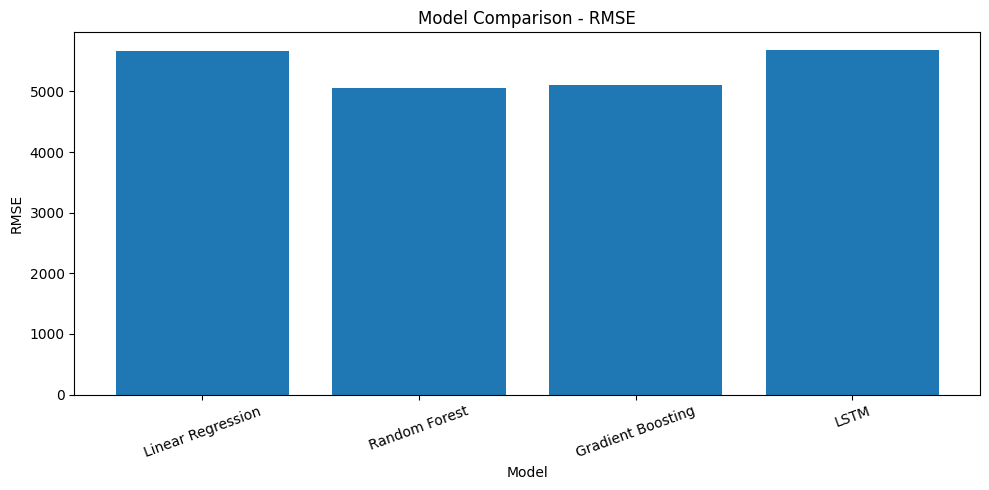

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["RMSE"]
)

plt.xlabel("Model")
plt.ylabel("RMSE")
plt.title("Model Comparison - RMSE")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [ ]:
comparison_path = "/content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/model_comparison_results.csv"

model_comparison.to_csv(
    comparison_path,
    index=False
)

print("Model comparison saved successfully!")
print("Path:", comparison_path)

Model comparison saved successfully!
Path: /content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/model_comparison_results.csv


In [ ]:
# Calculate Q1 and Q3
Q1 = model_data["Total_Expense"].quantile(0.25)
Q3 = model_data["Total_Expense"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Define anomaly boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify anomalies
model_data["Anomaly"] = (
    (model_data["Total_Expense"] < lower_bound) |
    (model_data["Total_Expense"] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of anomalies:", model_data["Anomaly"].sum())

print("\nAnomalous months:")
print(
    model_data.loc[
        model_data["Anomaly"],
        ["Year_Month", "Total_Expense"]
    ]
)

Q1: 16726.65
Q3: 23807.3
IQR: 7080.649999999998
Lower Bound: 6105.675000000005
Upper Bound: 34428.274999999994

Number of anomalies: 0

Anomalous months:
Empty DataFrame
Columns: [Year_Month, Total_Expense]
Index: []


In [ ]:
anomaly_summary = pd.DataFrame({
    "Metric": [
        "Total Months",
        "Anomalous Months",
        "Normal Months",
        "Anomaly Percentage"
    ],
    "Value": [
        len(model_data),
        int(model_data["Anomaly"].sum()),
        int((~model_data["Anomaly"]).sum()),
        round(model_data["Anomaly"].mean() * 100, 2)
    ]
})

print(anomaly_summary)

               Metric  Value
0        Total Months   57.0
1    Anomalous Months    0.0
2       Normal Months   57.0
3  Anomaly Percentage    0.0


In [ ]:
# Calculate basic spending statistics
average_monthly_expense = model_data["Total_Expense"].mean()
highest_monthly_expense = model_data["Total_Expense"].max()
lowest_monthly_expense = model_data["Total_Expense"].min()

print("Average Monthly Expense:", round(average_monthly_expense, 2))
print("Highest Monthly Expense:", round(highest_monthly_expense, 2))
print("Lowest Monthly Expense:", round(lowest_monthly_expense, 2))

Average Monthly Expense: 20690.63
Highest Monthly Expense: 31386.8
Lowest Monthly Expense: 9996.66


In [ ]:
recommendations = []

if average_monthly_expense > 20000:
    recommendations.append(
        "Your average monthly expense is above ₹20,000. Consider setting a monthly spending limit."
    )

if highest_monthly_expense > average_monthly_expense * 1.3:
    recommendations.append(
        "Your highest spending month was significantly higher than your average. Review that month's expenses to identify unnecessary spending."
    )

if lowest_monthly_expense < average_monthly_expense * 0.6:
    recommendations.append(
        "Your lowest spending month was much lower than your average. This indicates that spending can potentially be reduced in some months."
    )

if len(recommendations) == 0:
    recommendations.append(
        "Your monthly spending appears relatively stable. Continue monitoring your expenses regularly."
    )

print("Personalized Financial Recommendations")
print("----------------------------------------")

for i, recommendation in enumerate(recommendations, 1):
    print(f"{i}. {recommendation}")

Personalized Financial Recommendations
----------------------------------------
1. Your average monthly expense is above ₹20,000. Consider setting a monthly spending limit.
2. Your highest spending month was significantly higher than your average. Review that month's expenses to identify unnecessary spending.
3. Your lowest spending month was much lower than your average. This indicates that spending can potentially be reduced in some months.


In [ ]:
anomaly_output_path = "/content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/monthly_expense_anomalies.csv"

model_data.to_csv(
    anomaly_output_path,
    index=False
)

print("Anomaly dataset saved successfully!")
print("Path:", anomaly_output_path)
print("Shape:", model_data.shape)

Anomaly dataset saved successfully!
Path: /content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/monthly_expense_anomalies.csv
Shape: (57, 14)


In [ ]:
prediction_results = pd.DataFrame({
    "Year_Month": model_data.iloc[split_index:]["Year_Month"].values,
    "Actual_Expense": y_test.values,
    "Random_Forest_Prediction": random_forest_predictions,
    "Gradient_Boosting_Prediction": gradient_boosting_predictions
})

print(prediction_results.round(2))

   Year_Month  Actual_Expense  Random_Forest_Prediction  \
0     2024-01        29916.13                  23754.43   
1     2024-02        23807.30                  20242.47   
2     2024-03        16436.43                  21740.49   
3     2024-04        15443.17                  21948.30   
4     2024-05        15822.56                  17826.50   
5     2024-06        22554.07                  19372.18   
6     2024-07        27716.08                  22018.03   
7     2024-08        22933.69                  22586.40   
8     2024-09        19383.94                  22536.67   
9     2024-10        22984.21                  21689.34   
10    2024-11        23565.96                  21491.90   
11    2024-12        10938.92                  22065.89   

    Gradient_Boosting_Prediction  
0                       23704.03  
1                       19907.70  
2                       21680.05  
3                       19272.21  
4                       18386.62  
5                     

In [ ]:
prediction_results["RF_Absolute_Error"] = abs(
    prediction_results["Actual_Expense"] -
    prediction_results["Random_Forest_Prediction"]
)

prediction_results["GB_Absolute_Error"] = abs(
    prediction_results["Actual_Expense"] -
    prediction_results["Gradient_Boosting_Prediction"]
)

print(prediction_results.round(2))

   Year_Month  Actual_Expense  Random_Forest_Prediction  \
0     2024-01        29916.13                  23754.43   
1     2024-02        23807.30                  20242.47   
2     2024-03        16436.43                  21740.49   
3     2024-04        15443.17                  21948.30   
4     2024-05        15822.56                  17826.50   
5     2024-06        22554.07                  19372.18   
6     2024-07        27716.08                  22018.03   
7     2024-08        22933.69                  22586.40   
8     2024-09        19383.94                  22536.67   
9     2024-10        22984.21                  21689.34   
10    2024-11        23565.96                  21491.90   
11    2024-12        10938.92                  22065.89   

    Gradient_Boosting_Prediction  RF_Absolute_Error  GB_Absolute_Error  
0                       23704.03            6161.70            6212.10  
1                       19907.70            3564.83            3899.60  
2            

In [ ]:
prediction_output_path = "/content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/monthly_expense_predictions.csv"

prediction_results.to_csv(
    prediction_output_path,
    index=False
)

print("Prediction results saved successfully!")
print("Path:", prediction_output_path)
print("Rows:", len(prediction_results))
print("Columns:", len(prediction_results.columns))

Prediction results saved successfully!
Path: /content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/monthly_expense_predictions.csv
Rows: 12
Columns: 6


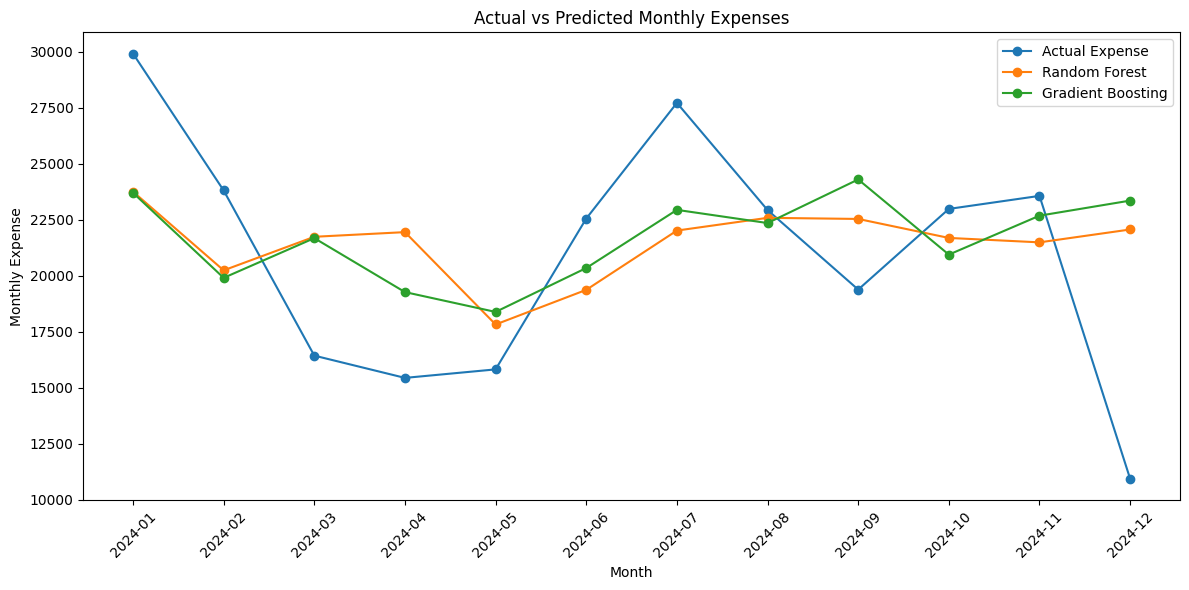

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    prediction_results["Year_Month"],
    prediction_results["Actual_Expense"],
    marker="o",
    label="Actual Expense"
)

plt.plot(
    prediction_results["Year_Month"],
    prediction_results["Random_Forest_Prediction"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    prediction_results["Year_Month"],
    prediction_results["Gradient_Boosting_Prediction"],
    marker="o",
    label="Gradient Boosting"
)

plt.xlabel("Month")
plt.ylabel("Monthly Expense")
plt.title("Actual vs Predicted Monthly Expenses")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance")
print("---------------------------------")
print(feature_importance.round(4))

Random Forest Feature Importance
---------------------------------
                      Feature  Importance
3        Expense_2_Months_Ago      0.2805
2      Previous_Month_Expense      0.2029
1                       Month      0.1594
4        Expense_3_Months_Ago      0.1267
6     Three_Month_Avg_Expense      0.0854
5  Previous_Transaction_Count      0.0831
0                        Year      0.0619


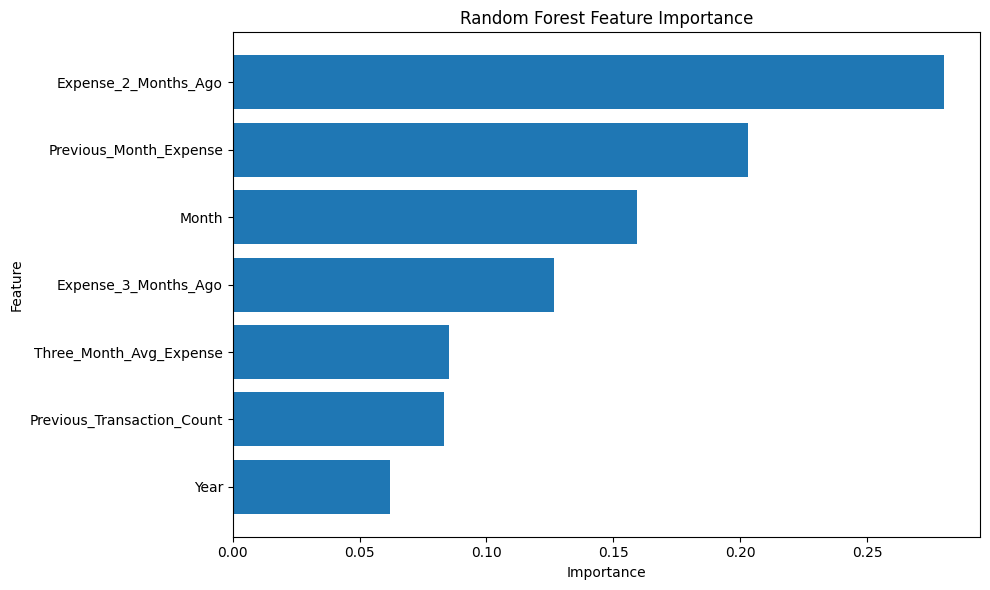

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
feature_importance_path = "/content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/random_forest_feature_importance.csv"

feature_importance.to_csv(
    feature_importance_path,
    index=False
)

print("Feature importance saved successfully!")
print("Path:", feature_importance_path)

Feature importance saved successfully!
Path: /content/drive/MyDrive/AI-Personal-Finance-Management/ml/datasets/processed/random_forest_feature_importance.csv
